In [1]:
import os
import pandas as pd
_read_csv = pd.read_csv
def _read_csv_compat(path, *args, **kwargs):
    frame = _read_csv(path, *args, **kwargs)
    if str(path).endswith('planning/generation.csv') or str(path).endswith('planning\\generation.csv'):
        frame['technology'] = frame['carrier']
        frame['published_year'] = frame['commissioning_year']
    return frame
pd.read_csv = _read_csv_compat

INFO:pypsa.io:Imported network network_solved_2022.nc has buses, carriers, generators, lines, links, loads, transformers


C:\Users\fpenaherrera_vaca\AppData\Local\Temp\ipykernel_13408\2958764015.py:13: FutureWarning:

DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.



INFO:pypsa.io:Imported network tendencial_2030.solved.nc has buses, carriers, generators, lines, links, loads, transformers


C:\Users\fpenaherrera_vaca\AppData\Local\Temp\ipykernel_13408\2958764015.py:13: FutureWarning:

DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.



INFO:pypsa.io:Imported network expansion_2030.solved.nc has buses, carriers, generators, lines, links, loads, transformers


C:\Users\fpenaherrera_vaca\AppData\Local\Temp\ipykernel_13408\2958764015.py:13: FutureWarning:

DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.



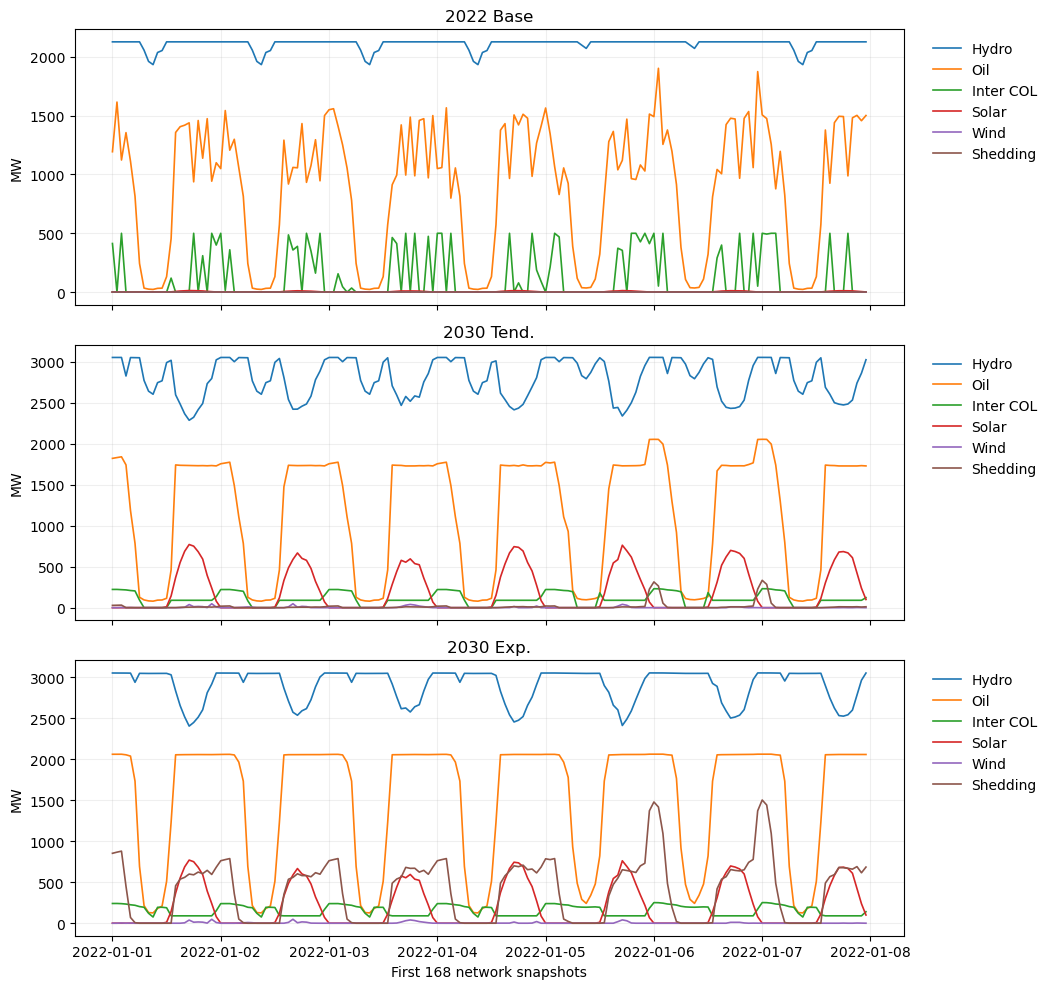

In [2]:
# Corrected representative-week traces: actual network snapshots and explicit line series.
from pathlib import Path
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir(): ROOT = ROOT.parent
import pypsa
TRACE_LABELS = {'2022 Base': ROOT / 'results/phase_06d/baseline/network_solved_2022.nc', '2030 Tend.': ROOT / 'results/phase_08/tendencial_2030.solved.nc', '2030 Exp.': ROOT / 'results/phase_08/expansion_2030.solved.nc'}
TRACE_CARRIERS = {'hydro':'Hydro', 'oil':'Oil', 'interconnection_colombia':'Inter COL', 'solar':'Solar', 'onwind':'Wind', 'load_shedding':'Shedding'}
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (label, path) in zip(axes, TRACE_LABELS.items()):
    trace_network = pypsa.Network(path)
    trace_snapshots = trace_network.snapshots[:168]
    dispatch = trace_network.generators_t.p.loc[trace_snapshots].mul(trace_network.generators.sign, axis=1).groupby(trace_network.generators.carrier, axis=1).sum()
    for carrier, nice in TRACE_CARRIERS.items():
        if carrier in dispatch: ax.plot(dispatch.index, dispatch[carrier], label=nice, linewidth=1.2)
    ax.set_title(label); ax.set_ylabel('MW'); ax.grid(alpha=0.2); ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
axes[-1].set_xlabel('First 168 network snapshots')
fig.tight_layout(rect=[0, 0, 0.82, 1]); fig.savefig(ROOT / 'reports/figures/phase_08/phase08_representative_week_dispatch.png', dpi=180); plt.show()

# Phase 08 — Minimal 2030 Master Plan screening

This experiment asks one narrow question: if the renewable projects published for 2023–2030 are represented as aggregate additions to the 2022 network, is the projected 2030 demand served? It is a screening exercise, not a claim that the published projects are electrically model-ready.

The 2022 network, hourly profiles, and reported fleet are retained. Future projects are added as aggregate renewable generators at a proxy bus because Phase 07 found unresolved substations and connections. Colombia imports are allowed up to the operator-supported 450 MW interconnection ceiling; the 2022 annual import-energy band is not carried into the future. Two demand cases are run: Tendencial and Expansion. Load shedding remains visible and is reported as a feasibility indicator.

In [3]:
from pathlib import Path
import sys, json, hashlib, shutil
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir(): ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
RESULTS = ROOT / 'results/phase_08'
FIGURES = ROOT / 'reports/figures/phase_08'
RESULTS.mkdir(parents=True, exist_ok=True); FIGURES.mkdir(parents=True, exist_ok=True)
NETWORK_PATH = ROOT / 'data/processed/networks/network_base_filled.nc'
PLANNING_PATH = ROOT / 'data/processed/planning/generation.csv'
DEMAND_PATH = ROOT / 'data/processed/demand/demand_prognosis_2022_2050.csv'
for p in (NETWORK_PATH, PLANNING_PATH, DEMAND_PATH):
    if not p.exists(): raise FileNotFoundError(p)
print('Inputs present:', NETWORK_PATH.name, PLANNING_PATH.name, DEMAND_PATH.name)

Inputs present: network_base_filled.nc generation.csv demand_prognosis_2022_2050.csv


## Assumptions and provenance

- Demand: the published 2030 `Tendencial` (38,042 GWh) and `Expansion` (46,084 GWh) forecasts are applied as a uniform multiplier to the 2022 hourly shape.
- Renewable additions: rows in the Phase 07 normalized generation table with published year 2023–2030 and technologies hydroelectric, photovoltaic, or eólico. The table is source-traceable to *Anexos ajuste PME 2023–2032*.
- Network: no new lines, substations, or generator-specific connections are inferred. Aggregate additions are attached to bus 84 as a transparent electrical proxy.
- Colombia: 450 MW aggregate import ceiling, supported by the CENACE/XM operator announcements supplied by the owner. This is a capacity ceiling, not a forecast of actual imports.
- Load shedding is not hidden or used as normal generation. Results with shedding are technically insufficient for the stated demand case.
- CO₂ is a model-side dispatch indicator using the network’s existing generator emission attributes where available; it is not a lifecycle assessment.

In [4]:
network = pypsa.Network(NETWORK_PATH)
planning = pd.read_csv(PLANNING_PATH)
forecast = pd.read_csv(DEMAND_PATH)
print(network.snapshots.size, 'snapshots; baseline demand', round(network.loads_t.p_set.sum().sum()/1000, 2), 'GWh')
print('baseline Colombia link capacity', network.links.loc[network.links.carrier.eq('interconnection_colombia'), 'p_nom'].sum(), 'MW')
# Renewable additions only; no nuclear or thermal additions are included.
tech = planning['technology'].astype(str).str.lower()
renewable = planning[planning['published_year'].between(2023, 2030) & tech.str.contains('hidro|fotovolta|eólic|eolic')].copy()
renewable['carrier_2030'] = np.select([tech.loc[renewable.index].str.contains('hidro'), tech.loc[renewable.index].str.contains('fotovolta'), tech.loc[renewable.index].str.contains('eólic|eolic')], ['hydro','solar','onwind'], default='other')
renewable['normalized_value'] = pd.to_numeric(renewable['normalized_value'], errors='coerce')
renewable = renewable.dropna(subset=['normalized_value'])
additions = renewable.groupby('carrier_2030').normalized_value.sum().rename('planned_addition_mw')
display(renewable[['project_id','official_name','published_year','technology','normalized_value','carrier_2030']])
display(additions.to_frame())

INFO:pypsa.io:Imported network network_base_filled.nc has buses, carriers, generators, lines, links, loads, transformers


8760 snapshots; baseline demand 27753.19 GWh
baseline Colombia link capacity 500.0 MW


,project_id,official_name,published_year,technology,normalized_value,carrier_2030
0,PME26_A_001,Sarapullo,2023,Hidroeléctrico,49.00,hydro
1,PME26_A_002,Minas de Huascachaca,2023,Eólico,50.00,onwind
2,PME26_A_003,Huayquichuma,2023,Hidroeléctrico,6.50,hydro
4,PME26_A_005,Alluriquín,2024,Hidroeléctrico,205.40,hydro
5,PME26_A_006,El Aromo,2025,Fotovoltaico,200.00,solar
6,PME26_A_007,Villonaco III,2025,Eólico,110.00,onwind
9,PME26_A_010,Mazar-Dudas: San Antonio,2026,Hidroeléctrico,7.19,hydro
10,PME26_A_011,Chorrillos,2026,Hidroeléctrico,4.00,hydro
11,PME26_A_012,Bloque 1 ERNC: Fotovoltaico - 318 MW,2026,Fotovoltaico,317.60,solar
12,PME26_A_013,Mazar-Dudas: Dudas,2026,Hidroeléctrico,6.82,hydro


,planned_addition_mw
carrier_2030,
hydro,1653.95
onwind,615.00
solar,1397.60


In [5]:
def mean_profile(n, carrier):
    cols = n.generators.index[n.generators.carrier.eq(carrier)]
    if len(cols) == 0: return pd.Series(1.0, index=n.snapshots)
    p = n.generators_t.p_max_pu[cols].mean(axis=1).reindex(n.snapshots).fillna(0.0)
    return p.clip(0, 1)

def build_case(label, demand_gwh):
    n = network.copy()
    # Uniform scaling preserves the observed spatial and hourly demand shape.
    base = n.loads_t.p_set.copy()
    n.loads_t.p_set = base * ((demand_gwh * 1000) / base.sum().sum())
    # Future import policy: operator-supported instantaneous ceiling, no 2022 energy band.
    mask = n.links.carrier.eq('interconnection_colombia')
    n.links.loc[mask, 'p_nom'] = n.links.loc[mask, 'p_nom'] * (450.0 / n.links.loc[mask, 'p_nom'].sum())
    bus = '84' if '84' in n.buses.index else n.buses.index[0]
    for carrier, capacity in additions.items():
        if capacity <= 0: continue
        name = f'phase08_{carrier}_planned_2023_2030'
        n.add('Generator', name, bus=bus, carrier=carrier, p_nom=float(capacity),
              marginal_cost=0.1 if carrier != 'hydro' else 0.2, sign=1.0,
              p_max_pu=mean_profile(n, carrier).to_numpy())
    # Preserve the source network and expose policy in metadata.
    n.meta = dict(n.meta or {})
    n.meta.update({'phase': '08', 'case': label, 'future_year': 2030,
                   'demand_gwh': demand_gwh, 'colombia_import_ceiling_mw': 450.0,
                   'renewable_additions_source': str(PLANNING_PATH.relative_to(ROOT)),
                   'network_status': 'screening_proxy_not_expanded_grid'})
    return n

def solve_case(label, demand_gwh):
    n = build_case(label, demand_gwh)
    log = RESULTS / f'{label}_highs.log'
    status, termination = n.optimize(solver_name='highs', solver_options={'threads': 1}, log_fn=str(log))
    shed = n.generators_t.p.loc[:, n.generators.carrier.eq('load_shedding')].sum().sum() / 1000
    total = n.loads_t.p_set.sum().sum() / 1000
    gen = n.generators_t.p.mul(n.generators.sign, axis=1).sum()
    by_carrier = gen.groupby(n.generators.carrier).sum().div(1000)
    imports = by_carrier.get('interconnection_colombia', 0.0)
    result = {'case': label, 'demand_gwh': total, 'solver_status': str(status), 'termination_condition': str(termination),
              'load_shedding_gwh': float(shed), 'load_shedding_pct': float(100*shed/total),
              'colombia_import_gwh': float(imports), 'planned_renewable_capacity_mw': float(additions.sum()),
              'generation_by_carrier_gwh': by_carrier.to_dict()}
    (RESULTS / f'{label}_summary.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    # Release the large Linopy/HiGHS model before serializing this case.
    n.model = None
    import gc; gc.collect()
    n.export_to_netcdf(RESULTS / f'{label}.solved.nc')
    return n, result

forecast2030 = forecast.loc[forecast.Year.eq(2030)].iloc[0]
scenarios = {'tendencial_2030': float(forecast2030.Tendencial), 'expansion_2030': float(forecast2030.Expansion)}
print('Scenario demand (GWh):', scenarios)

Scenario demand (GWh): {'tendencial_2030': 38042.0, 'expansion_2030': 46084.0}


## Full-year solves

The next cell runs two 8,760-hour HiGHS optimizations and writes solved NetCDF networks plus summaries into `results/phase_08/`.

In [6]:
selected = os.environ.get('ECUADOR_SCENARIO_ONLY')
if selected: scenarios = {selected: scenarios[selected]}
solved = {}
for label, demand in scenarios.items():
    n, solved[label] = solve_case(label, demand)
summary = pd.DataFrame(solved).T
summary['generation_by_carrier_gwh'] = summary['generation_by_carrier_gwh'].map(json.dumps)
summary.to_csv(RESULTS / 'scenario_summary.csv')
display(summary[['solver_status','termination_condition','demand_gwh','planned_renewable_capacity_mw','colombia_import_gwh','load_shedding_gwh','load_shedding_pct']])

INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.model:Solver logs written to `C:\Repositories\Repos\pypsa-earth-project\EcuadorElectricGrid\results\phase_08\tendencial_2030_highs.log`.


INFO:linopy.model:Solver options:
 - threads: 1


INFO:linopy.io:Writing objective.


Writing constraints.:   0%|          | 0/11 [00:00<?, ?it/s]

...

INFO:linopy.solvers:Log file at C:\Repositories\Repos\pypsa-earth-project\EcuadorElectricGrid\results\phase_08\tendencial_2030_highs.log


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 3363840 primals, 7927800 duals
Objective: 1.27e+11
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Transformer-fix-s-lower, Transformer-fix-s-upper, Link-fix-p-lower, Link-fix-p-upper, Kirchhoff-Voltage-Law were not assigned to the network.


INFO:pypsa.io:Exported network 'tendencial_2030.solved.nc' contains: lines, transformers, generators, loads, links, buses, carriers


,solver_status,termination_condition,demand_gwh,planned_renewable_capacity_mw,colombia_import_gwh,load_shedding_gwh,load_shedding_pct
tendencial_2030,ok,optimal,38042.0,3666.55,604.428015,124.985306,0.328546


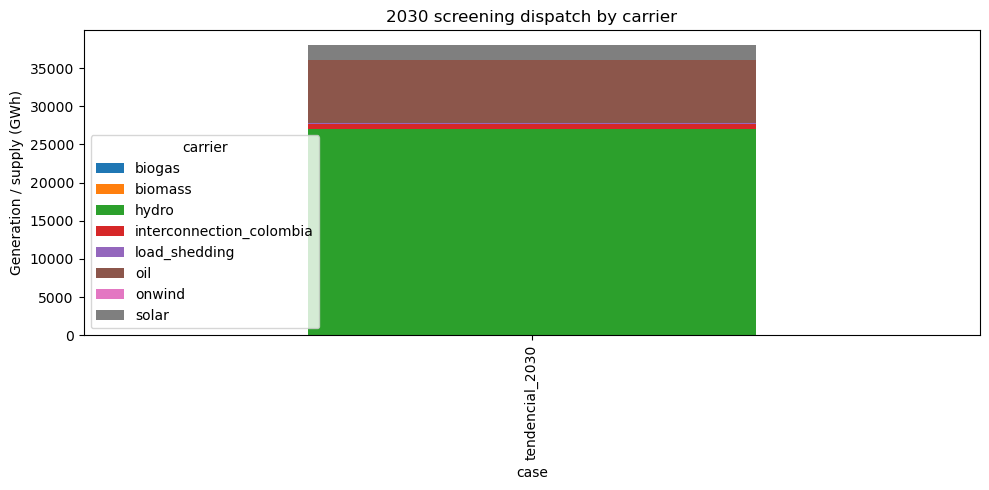

,case,demand_gwh,planned_renewable_capacity_mw,colombia_import_gwh,load_shedding_gwh,load_shedding_pct
tendencial_2030,tendencial_2030,38042.0,3666.55,604.428015,124.985306,0.328546


Solved notebooks/results are written under C:\Repositories\Repos\pypsa-earth-project\EcuadorElectricGrid\results\phase_08


In [7]:
# Comparison plots: carrier mix and annual indicators.
rows=[]
for label, data in solved.items():
    for carrier, value in data['generation_by_carrier_gwh'].items(): rows.append({'case':label,'carrier':carrier,'gwh':value})
mix = pd.DataFrame(rows); mix.to_csv(RESULTS/'generation_by_carrier.csv', index=False)
fig, ax = plt.subplots(figsize=(10,5)); mix.pivot(index='case', columns='carrier', values='gwh').plot.bar(stacked=True, ax=ax); ax.set_ylabel('Generation / supply (GWh)'); ax.set_title('2030 screening dispatch by carrier'); fig.tight_layout(); fig.savefig(FIGURES/'phase08_generation_mix.png', dpi=180); plt.show()
ind = summary[['case','demand_gwh','planned_renewable_capacity_mw','colombia_import_gwh','load_shedding_gwh','load_shedding_pct']].copy(); ind.to_csv(RESULTS/'indicators.csv', index=False); display(ind)
print('Solved notebooks/results are written under', RESULTS)

## Interpretation guardrail

A zero-shedding case would show that the proxy system can serve the selected demand under these dispatch assumptions. Any shedding means the represented portfolio and retained network are insufficient in this experiment. This cannot be attributed solely to missing generation: the grid proxy omits the Master Plan transmission/substation works and places aggregate projects at one bus. Import use near 450 MW indicates interconnection dependence. CO₂ comparisons should use the reported dispatch by carrier and the model’s emission factors, while clearly separating operational emissions from lifecycle or construction impacts.

The solved notebooks are copied by the runner to the Phase 08 results directory for inspection.